# Random Forest para Regresión (Random Forest Regressor)

## Objetivo

El objetivo de este notebook es desarrollar un modelo de aprendizaje supervisado capaz de predecir la popularidad de canciones de Spotify a partir de sus características musicales.

Se utilizará `RandomForestRegressor` de Scikit-learn, un algoritmo de ensamble que combina múltiples árboles de decisión para generar predicciones de regresión. Cada árbol aprende patrones a partir de los datos y el modelo combina sus predicciones, generalmente mediante un promedio, para obtener una estimación final.

La variable objetivo será `popularity`, mientras que las variables predictoras corresponderán a las características disponibles en el dataset de regresión preprocesado.

El desempeño del modelo se evaluará mediante validación cruzada, métricas de error, comparación entre valores reales y predichos e importancia de las variables.

In [10]:
import pandas as pd
import numpy as np
import os
import sys

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

"""
En caso de que Python no encuentre en la ruta los otros directorios,
ejecutar esta configuración
"""

sys.path.append(os.path.abspath(".."))

---

## Carga de los conjuntos de datos

Se cargan los datasets de entrenamiento y prueba previamente preprocesados para la tarea de regresión.

- **Conjunto de entrenamiento:** se utiliza para realizar la validación cruzada y ajustar el modelo definitivo.
- **Conjunto de prueba:** se reserva para evaluar la capacidad de generalización del modelo sobre observaciones que no participaron en su entrenamiento.

Se crean copias de ambos datasets y se inspeccionan sus primeras filas para comprobar la estructura y el contenido de los datos antes de continuar con el análisis.

In [11]:
data_train = pd.read_csv(
    "../../../dataset/Spotify_train_preprocesado_regresion.csv"
)

data_test = pd.read_csv(
    "../../../dataset/Spotify_test_preprocesado_regresion.csv"
)

df_train = data_train.copy()
df_test = data_test.copy()

print("Dataset de entrenamiento:")
display(df_train.head())

print("\nDataset de prueba:")
display(df_test.head())

Dataset de entrenamiento:


,bin__track_genre_0,bin__track_genre_1,bin__track_genre_2,bin__track_genre_3,bin__track_genre_4,bin__track_genre_5,bin__track_genre_6,ord__duration_category,num__danceability,num__energy,...,num__loudness,num__mode,num__speechiness,num__acousticness,num__instrumentalness,num__liveness,num__valence,num__tempo,num__duration_min,popularity
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.360656,0.407609,0.005418,...,-0.557598,0.751125,-0.804229,0.532848,-0.562123,-0.436477,1.542740,-0.147610,-0.695300,21.0
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.360656,0.100464,-0.034422,...,-0.017461,0.751125,-0.785413,0.623235,-0.606882,-0.678120,1.183864,0.437714,-0.191994,0.0
2,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.927115,-1.881489,0.216573,...,0.430609,0.751125,-0.519639,-0.618079,-0.580263,-0.985860,-1.305115,0.437984,0.625209,45.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.360656,1.746296,0.336094,...,0.571210,-1.331337,-0.500823,-0.710274,-0.606882,-0.635477,-0.506326,0.064335,-0.879964,4.0
4,0.0,0.0,0.0,0.0,1.0,0.0,1.0,-0.360656,0.726344,-1.795371,...,-2.390784,-1.331337,1.124396,1.430692,1.793755,-0.671013,1.195440,2.664353,-0.772929,55.0



Dataset de prueba:


,bin__track_genre_0,bin__track_genre_1,bin__track_genre_2,bin__track_genre_3,bin__track_genre_4,bin__track_genre_5,bin__track_genre_6,ord__duration_category,num__danceability,num__energy,...,num__loudness,num__mode,num__speechiness,num__acousticness,num__instrumentalness,num__liveness,num__valence,num__tempo,num__duration_min,popularity
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.927115,-1.452645,-1.914892,...,-2.318107,0.751125,-0.700742,1.813330,1.793755,-0.700153,-1.619613,-0.133029,1.330330,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.360656,1.798453,0.626930,...,1.478109,0.751125,0.865678,-0.675324,-0.606764,1.390062,1.450127,-0.406397,-0.528812,1.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.360656,0.639416,0.224541,...,0.842404,0.751125,-0.199770,-0.940037,-0.606785,-0.724317,1.303489,2.353574,-0.550148,7.0
3,1.0,0.0,0.0,0.0,1.0,1.0,0.0,-1.648427,-0.067596,0.754419,...,0.438615,0.751125,2.126046,1.707878,-0.606882,2.409939,0.292462,-1.350621,-1.566635,23.0
4,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.927115,0.830657,1.093063,...,1.257701,0.751125,-0.380872,-0.942719,1.793755,-1.048403,1.006355,0.096426,1.158399,0.0


---

## Separación de variables predictoras y variable objetivo

Se separan las variables independientes de la variable dependiente que el modelo debe predecir.

- **Variables predictoras (`X_train`, `X_test`):** contienen las características utilizadas para estimar la popularidad de las canciones.
- **Variable objetivo (`y_train`, `y_test`):** corresponde a `popularity`, que representa la popularidad numérica de cada canción.

La columna `popularity` se elimina de las variables predictoras para evitar que el modelo utilice directamente el valor que debe aprender a estimar.

Esta separación permite entrenar el modelo con los datos de entrenamiento y evaluar sus predicciones con observaciones que no participaron en el ajuste final.

In [12]:
# Separación de variables predictoras y objetivo
X_train = df_train.drop(
    columns=["popularity"]
)

y_train = df_train[
    "popularity"
]

X_test = df_test.drop(
    columns=["popularity"]
)

y_test = df_test[
    "popularity"
]

---

## Configuración y validación cruzada del modelo

Se construye un modelo `RandomForestRegressor` con los siguientes parámetros:

- `n_estimators=100`: utiliza 100 árboles de decisión para construir el ensamble.
- `random_state=42`: fija la semilla aleatoria para favorecer la reproducibilidad.
- `n_jobs=-1`: permite utilizar los procesadores disponibles durante el entrenamiento del modelo.

Para evaluar su desempeño, se utiliza validación cruzada con `KFold`, configurada con cinco particiones, mezcla aleatoria de las observaciones y una semilla fija.

Se consideran cuatro métricas:

- **MAE:** error absoluto medio entre los valores reales y las predicciones.
- **MSE:** error cuadrático medio, que penaliza con mayor intensidad los errores grandes.
- **RMSE:** raíz del error cuadrático medio, expresada en la misma escala que la variable objetivo.
- **R²:** coeficiente de determinación, que permite evaluar la capacidad explicativa del modelo.

La función `cross_validate` calcula las métricas en cada partición. El parámetro `return_train_score=False` indica que solo se almacenan las métricas de validación, sin calcular las correspondientes al entrenamiento.

Además, `n_jobs=1` en `cross_validate` evita ejecutar las particiones en paralelo desde esa función, mientras que el propio modelo puede utilizar múltiples procesadores durante el entrenamiento de cada bosque.

In [13]:
modelo_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

resultados_cv = cross_validate(
    modelo_rf,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

resultados_arbol = {
    "MAE": -resultados_cv["test_mae"].mean(),
    "MSE": -resultados_cv["test_mse"].mean(),
    "RMSE": -resultados_cv["test_rmse"].mean(),
    "R2": resultados_cv["test_r2"].mean()
}

desviaciones_arbol = {
    "MAE": resultados_cv["test_mae"].std(),
    "MSE": resultados_cv["test_mse"].std(),
    "RMSE": resultados_cv["test_rmse"].std(),
    "R2": resultados_cv["test_r2"].std()
}

print("Resultados de Decision Tree Regressor:")

for metrica, valor in resultados_arbol.items():
    print(f"{metrica}: {valor:.4f}")

print("\nDesviación estándar entre particiones:")

for metrica, valor in desviaciones_arbol.items():
    print(f"{metrica}: {valor:.4f}")

Resultados de Decision Tree Regressor:
MAE: 11.7245
MSE: 290.4368
RMSE: 17.0418
R2: 0.4145

Desviación estándar entre particiones:
MAE: 0.0681
MSE: 4.2322
RMSE: 0.1242
R2: 0.0081


## Resultados de la validación cruzada

Se calculan los promedios de las métricas obtenidas durante las cinco particiones de la validación cruzada.

Las métricas MAE, MSE y RMSE se obtienen inicialmente como valores negativos, debido a que Scikit-learn utiliza el prefijo `neg_` para representar funciones de puntuación en las que un valor mayor es preferible. Para facilitar su interpretación, se invierte el signo de los promedios.

También se calcula la desviación estándar de cada métrica para analizar la variabilidad de los resultados entre las particiones.

En términos generales, se busca minimizar MAE, MSE y RMSE, mientras que se busca maximizar R².

La comparación entre el promedio y la desviación estándar permite evaluar tanto el nivel de error como la estabilidad del modelo frente a distintas particiones de los datos de entrenamiento.

---

## Visualización de las métricas de validación cruzada

Se generan gráficos de barras para representar los resultados promedio obtenidos durante la validación cruzada.

El primer gráfico muestra los valores de MAE, MSE y RMSE, facilitando la revisión de los errores de predicción.

El segundo gráfico presenta el coeficiente de determinación R², que permite observar la capacidad explicativa del modelo.

Estas visualizaciones complementan los resultados numéricos y facilitan la comparación de las métricas.

**Consideración:** MAE, MSE y RMSE tienen escalas diferentes. El MSE se expresa en unidades al cuadrado, por lo que su valor no debe compararse directamente con MAE y RMSE como si representaran magnitudes equivalentes.

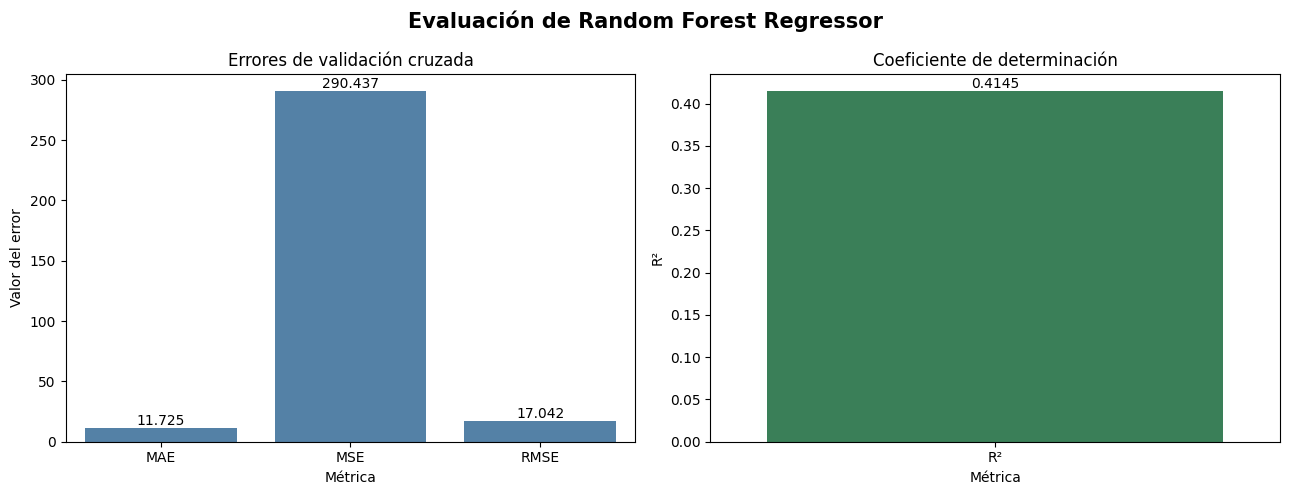

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metricas_error = ["MAE", "MSE", "RMSE"]

valores_error = [
    resultados_arbol[m]
    for m in metricas_error
]

sns.barplot(
    x=metricas_error,
    y=valores_error,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Errores de validación cruzada")
axes[0].set_xlabel("Métrica")
axes[0].set_ylabel("Valor del error")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f")

sns.barplot(
    x=["R²"],
    y=[resultados_arbol["R2"]],
    ax=axes[1],
    color="seagreen"
)

axes[1].set_title("Coeficiente de determinación")
axes[1].set_xlabel("Métrica")
axes[1].set_ylabel("R²")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.4f")

plt.suptitle(
    "Evaluación de Random Forest Regressor",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

---

## Evaluación del modelo sobre el conjunto de prueba

Se generan predicciones para las observaciones del conjunto de prueba mediante el método `predict`.

A partir de las predicciones y los valores reales de popularidad, se calculan las siguientes métricas:

- **MAE:** mide el error absoluto medio de las predicciones.
- **MSE:** calcula el promedio de los errores al cuadrado.
- **RMSE:** expresa el error cuadrático medio en la escala original de popularidad.
- **R²:** mide la capacidad del modelo para explicar la variabilidad de la variable objetivo en comparación con un predictor de referencia basado en la media.

El conjunto de prueba no debe utilizarse para ajustar el modelo ni seleccionar sus hiperparámetros. De esta manera, sus resultados ofrecen una estimación más independiente de la capacidad de generalización del modelo.

Un menor valor de MAE, MSE y RMSE indica menores errores. Un R² más alto suele indicar una mejor capacidad explicativa; si R² es negativo, el modelo obtiene un resultado inferior al predictor de referencia basado en la media del conjunto evaluado.

In [15]:
# Entrenar el modelo
modelo_rf.fit(X_train, y_train)

y_pred_arbol = modelo_rf.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_arbol)
mse_test = mean_squared_error(y_test, y_pred_arbol)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test, y_pred_arbol)

print("Resultados de Decision Tree Regressor en prueba:")
print(f"MAE:  {mae_test:.4f}")
print(f"MSE:  {mse_test:.4f}")
print(f"RMSE: {rmse_test:.4f}")
print(f"R2:   {r2_test:.4f}")

Resultados de Decision Tree Regressor en prueba:
MAE:  11.4387
MSE:  280.4767
RMSE: 16.7474
R2:   0.4339


---

## Comparación entre popularidad real y predicha

Se utiliza un gráfico de dispersión para comparar los valores reales de popularidad con las predicciones del modelo sobre el conjunto de prueba.

- **Eje X:** popularidad real de las canciones.
- **Eje Y:** popularidad predicha por Random Forest.
- **Línea roja discontinua:** referencia de predicción perfecta, donde la estimación coincide con el valor real.

Los puntos cercanos a la línea de referencia representan predicciones con menor error, mientras que los puntos alejados indican diferencias más grandes entre los valores reales y estimados.

La distribución de los puntos también permite observar posibles patrones de error, como una tendencia a sobreestimar o subestimar la popularidad en determinados rangos.

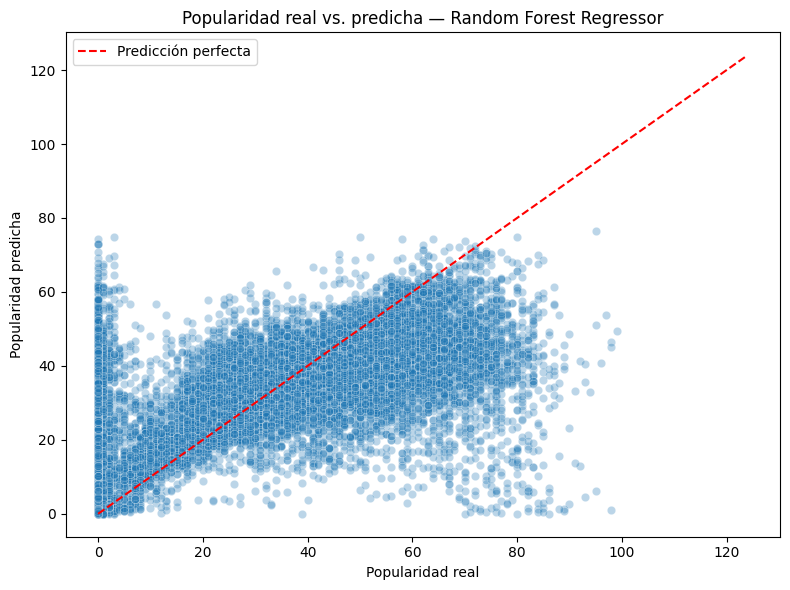

In [23]:

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_arbol,
    alpha=0.3
)

limite_min = min(y_test.min(), y_pred_arbol.min())
limite_max = max(y_test.max(), y_pred_arbol.max()) + 25

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    color="red",
    linestyle="--",
    label="Predicción perfecta"
)

plt.title("Popularidad real vs. predicha — Random Forest Regressor")
plt.xlabel("Popularidad real")
plt.ylabel("Popularidad predicha")
plt.legend()
plt.tight_layout()
plt.show()

---

## Análisis de la importancia de las variables

Se utiliza el atributo `feature_importances_` para obtener la importancia relativa de las variables predictoras en el modelo Random Forest.

Esta medida se basa en la contribución de las variables a las reducciones de impureza producidas por las divisiones de los árboles que componen el ensamble. En regresión, dichas divisiones buscan reducir la variabilidad de los valores objetivo dentro de los grupos resultantes.

Las importancias se organizan en orden descendente y se presentan las 15 variables con los valores más altos mediante una tabla y un gráfico de barras.

Este análisis permite identificar las características que tuvieron mayor participación en las decisiones de los árboles al predecir la popularidad.

**Consideración:** una importancia elevada no demuestra una relación causal con la popularidad. Asimismo, cuando existen variables correlacionadas, la importancia puede repartirse entre ellas o verse afectada por la estructura de los árboles. Por ello, los resultados deben interpretarse como una medida de relevancia dentro del modelo entrenado.

,Variable,Importancia
14,num__acousticness,0.088681
8,num__danceability,0.083222
11,num__loudness,0.078130
17,num__valence,0.076810
9,num__energy,0.076252
19,num__duration_min,0.075019
18,num__tempo,0.074880
13,num__speechiness,0.067262
16,num__liveness,0.062102
15,num__instrumentalness,0.056654


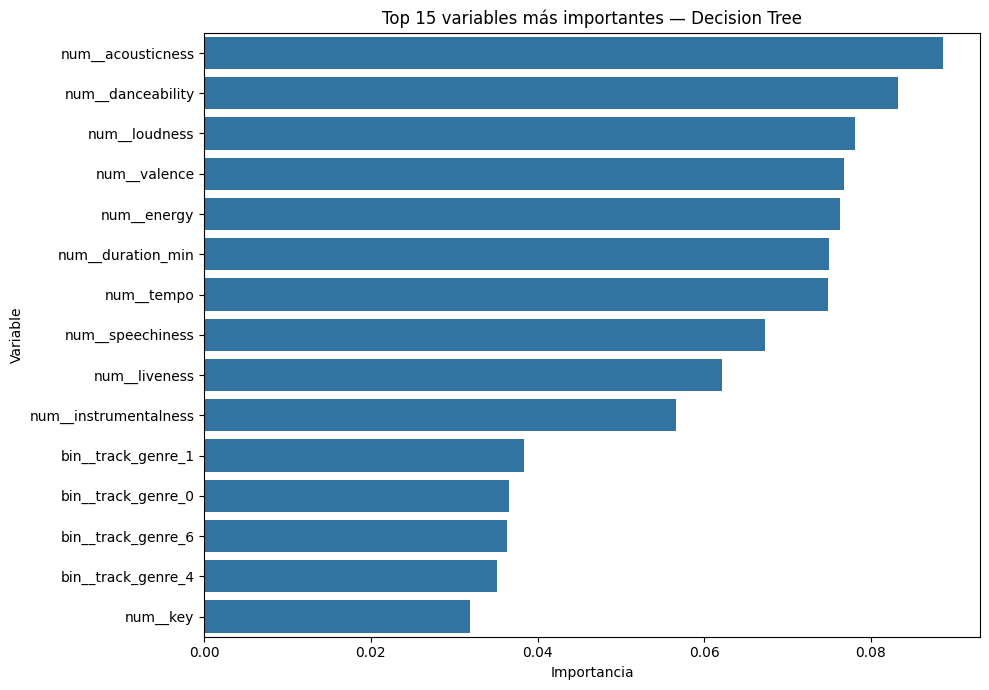

In [17]:
importancias_arbol = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": modelo_rf.feature_importances_
}).sort_values(
    by="Importancia",
    ascending=False
)

display(importancias_arbol.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importancias_arbol.head(15),
    x="Importancia",
    y="Variable"
)

plt.title("Top 15 variables más importantes — Decision Tree")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

---

## Conclusiones

En este notebook se desarrolló un modelo Random Forest Regressor para predecir la popularidad de canciones de Spotify a partir de sus características musicales.

La validación cruzada permitió evaluar el desempeño promedio del modelo y la variabilidad de sus métricas entre distintas particiones del conjunto de entrenamiento. Posteriormente, se calcularon las métricas de evaluación sobre un conjunto de prueba independiente.

La combinación de múltiples árboles de decisión permite capturar relaciones no lineales e interacciones entre variables. Sin embargo, el desempeño obtenido depende de los datos, de la configuración de los hiperparámetros y de la calidad del preprocesamiento.

Las métricas MAE, MSE, RMSE y R² permiten evaluar el error y la capacidad explicativa, mientras que el gráfico de dispersión y la importancia de las variables facilitan la interpretación de los resultados.

Finalmente, para determinar si Random Forest constituye una alternativa más adecuada que otros modelos de regresión, sus resultados deben compararse con los obtenidos mediante los mismos conjuntos de entrenamiento y prueba, utilizando las mismas métricas.